# 04 · Does caffeine show up?

Each day's drinks are lined up against that evening's night.
"Late" means anything logged at or after 14:00.

In [1]:
from sleep_patterns.caffeine import by_last_drink, caffeine_correlations, daily_caffeine, with_caffeine
from sleep_patterns.clean import nightly
from sleep_patterns.io import load_caffeine, load_sleep
from sleep_patterns import plots

caffeine = load_caffeine()
nights = nightly(load_sleep())
merged = with_caffeine(nights, caffeine)
daily_caffeine(caffeine).describe().round(1)

,total_mg,late_mg,drinks,last_drink
count,321.0,321.0,321.0,321.0
mean,189.9,51.0,2.4,12.9
std,112.5,71.6,1.3,3.7
min,34.0,0.0,1.0,6.2
25%,95.0,0.0,1.0,8.7
50%,176.0,0.0,2.0,13.6
75%,255.0,95.0,3.0,16.1
max,559.0,415.0,7.0,19.5


In [2]:
caffeine.groupby("drink")["caffeine_mg"].agg(["size", "sum"]).sort_values("sum", ascending=False)

,size,sum
drink,,
coffee,362,34390
espresso,157,9891
black tea,169,7943
energy drink,46,7360
cola,40,1360


In [3]:
caffeine_correlations(merged).round(3)

hours  efficiency  awakenings
method   caffeine                               
pearson  total_mg -0.298      -0.147       0.219
         late_mg  -0.423      -0.086       0.259
         drinks   -0.269      -0.134       0.253
spearman total_mg -0.275      -0.118       0.191
         late_mg  -0.367      -0.076       0.259
         drinks   -0.248      -0.115       0.219

Total caffeine matters a bit; caffeine *after 2pm* matters more, for both
duration and the number of awakenings. Efficiency barely moves.

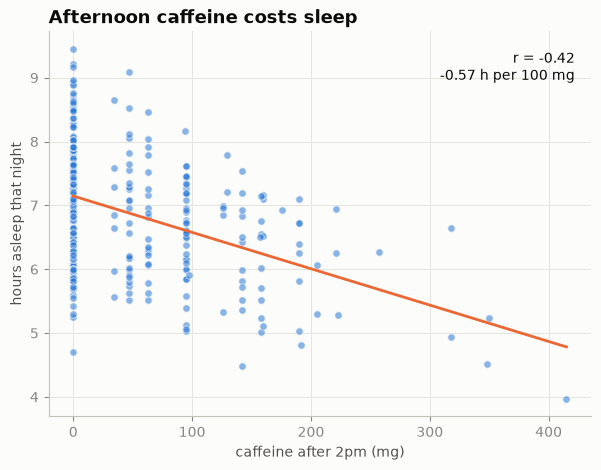

In [4]:
plots.caffeine_scatter(merged);

,nights,mean_hours
last_drink,,
none,42,7.05
00-12h,123,7.14
12-14h,43,7.28
14-16h,63,6.75
16-24h,82,6.34


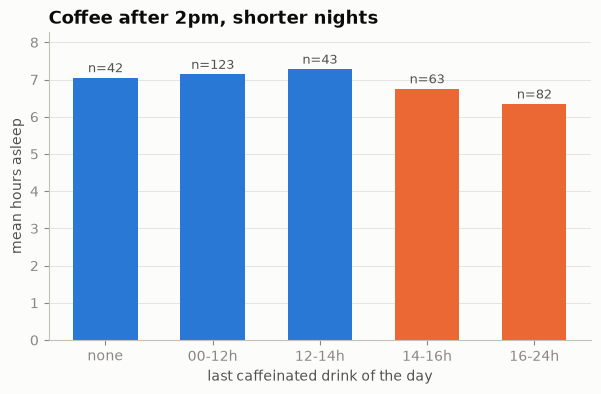

In [5]:
buckets = by_last_drink(merged)
plots.cutoff_bars(buckets)
buckets.round(2)

## Is it the coffee, or is it the deadlines?

The busiest months are also the most caffeinated ones, so some of that slope is just
"bad month". Holding month and weekday fixed shrinks it, but it doesn't go away.

In [6]:
import numpy as np
from sleep_patterns.caffeine import late_caffeine_effect

raw = np.polyfit(merged["late_mg"], merged["hours"], 1)[0]
adjusted = late_caffeine_effect(merged)
print(f"raw slope:      {raw * 100 * 60:+.0f} min per 100 mg after 2pm")
print(f"month+weekday:  {adjusted * 100 * 60:+.0f} min per 100 mg after 2pm")

raw slope:      -34 min per 100 mg after 2pm
month+weekday:  -29 min per 100 mg after 2pm


In [7]:
merged.groupby(merged["night"].dt.month)[["late_mg", "hours"]].mean().round(2)

,late_mg,hours
night,,
1,29.07,7.04
2,40.12,7.13
3,61.20,6.32
4,63.28,6.22
5,11.77,6.99
6,44.60,6.82
7,33.77,7.29
8,33.33,7.32
9,75.36,7.04
